In [75]:
import torch
import pandas as pd
import torch.nn.functional as F

In [76]:
df_relaxase = pd.read_csv("../data/processed/relaxase_oriT_dataset.csv")

df_rep = pd.read_csv("../data/processed/final_rep_virus_dataset.csv")

In [77]:
df_rep = df_rep[df_rep['match'] == 'Yes']

df_rep = df_rep.drop(columns=['taxid', 'virus_name', 'sDBM_sim_gap', 'ori_align_score', 'iteration_name', 'match'])

df_rep = df_rep.drop_duplicates(subset=["sDBM", "ori_seq"], keep='first')

df_rep.to_csv('../data/processed/unique_rep_oriR_dataset.csv', index=False)

df_rep

,sDBM_pos,sDBM,ori_seq,rep_amino_acid_seq
0,"(63, 71)",GAHFEKRRG,TAGTATTAC,MARQVICWCFTLNNPLSPLSLHDSMKYLVYQTEQGEAGNIHFQGYI...
1,"(63, 71)",GAHLEKRKG,TATTATTAC,MARYVVCWMFTINNPSSLPVMRDEIKYMVYQVERGQEGTRHVQGYV...
2,"(73, 81)",KPHLEKQRA,GACTGCTAC,MAAIKGQWWCFTVFFLTATAPDLVPLFENTHVSYACWQEEESPTTK...
3,"(70, 78)",RAHWEKARG,TAGTATTAC,MSASRWTFTLHYSDATERGKFLATLKEEDVHYAVVGDETAPNTGRK...
4,"(74, 82)",RAHFECAKG,CAGTATTAC,MAPRGNAAKRWTFTINNWTLADYDKVLEFTTKFEPVFLICGKERGE...
...,...,...,...,...
231,"(88, 96)",HPNIQGAKS,TAAAAATAC,MPRAGRFSIKAKNYFLTYPQCSLSKEEALSQLQNLITPTNKKYIKI...
232,"(88, 96)",HPNIQGAKS,TACTAATAC,MPPPNKFRINAKNYFLTYPRCSLTKEEALSQIKALETPISKLFIRI...
233,"(88, 96)",HPNVQGAKS,TTATACTAC,MAPPKRFQINAKNYFLTYPQCSLTKEEALSQLRSLRTPTNQKYIKV...
236,"(88, 96)",HPNIQGAKS,TTATCCTAC,MSRPKGFRVNAKNFFLTYPRCSLSKEAALEQLQNIQTNVNKKFIRV...


In [78]:
df_relaxase = df_relaxase.dropna(subset=['oriT_nic_seq'])

# remember to set sDBM threshold

df_relaxase = df_relaxase.drop(columns=['oriTDB_accession', 'oriTDB_id', 'nic site', 'sDBM_sim_gap'])

df_relaxase = df_relaxase.drop_duplicates(subset=["sDBM", "oriT_nic_seq"], keep='first')

df_relaxase

,relaxase_family,relaxase_sequence,host,sDBM,sDBM_pos,oriT_nic_seq
0,TraI,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,Pseudomonas aeruginosa,HVPMRSIKK,"(4, 12)",TATCCTGCC
2,MobA,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...,Escherichia coli,HLTAKTGSR,"(4, 12)",AAGTGCGCC
3,TaxC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,E. coli,VEKDYRVKR,"(4, 12)",TATCCTGCA
5,TraA,MTIAKRENGKRSLIAMASYRSGEKLYSELYEKTNLYNHRTVKPEAF...,Streptococcus agalactiae B-49813/75,IAKRENGKR,"(2, 10)",AAGTGCGCC
6,TraI,MLSISSIKGDAGYYSHEDNYYASGSLDSRWMGEGAEKLGLKGEVAS...,Salmonella typhi,SISSIKGDA,"(2, 10)",CGGGTGTGG
...,...,...,...,...,...,...
1336,Relaxase_PUP23_RS00120,MRNVKKSSFVELAKYLQDPQSKQERVGVIKVTNCHQENILDAARYD...,Escherichia coli strain LA172,VELAKYLQD,"(9, 17)",TGTCCTGCC
1371,Mob_Pre_PU712_RS19420,MGTVAAALQHCYRDRETPNADQERTPDNDHLAARSTDEAMGKLRER...,Proteus mirabilis strain CY32,AAALQHCYR,"(4, 12)",AAGTGCGCC
1376,MobF,MVLTRQDIGRAASYYEDGADDYYAKDGDASEWQGKGAEELGLSGEV...,Enterobacter hormaechei strain TUM10660,VLTRQDIGR,"(1, 9)",ATTGTCTAT
1379,Rep_trans_F1621_RS12210_SESURV_p2,MYSNSRLSGQTLGKSQPELSFDAMTIVGNLNKNNAQKLSEFMSVEP...,Staphylococcus epidermidis strain SESURV_p2_0614,TIVGNLNKN,"(24, 32)",TCGATTGGT


In [79]:
df_new_relaxase = df_relaxase.drop(columns=['relaxase_family', 'host'])

#reorder
df_new_relaxase = df_new_relaxase[["sDBM_pos", "sDBM", "oriT_nic_seq", "relaxase_sequence"]]

df_new_relaxase.to_csv('../data/processed/unique_relaxase_oriT_dataset.csv', index=False)

df_new_relaxase

,sDBM_pos,sDBM,oriT_nic_seq,relaxase_sequence
0,"(4, 12)",HVPMRSIKK,TATCCTGCC,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...
2,"(4, 12)",HLTAKTGSR,AAGTGCGCC,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...
3,"(4, 12)",VEKDYRVKR,TATCCTGCA,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...
5,"(2, 10)",IAKRENGKR,AAGTGCGCC,MTIAKRENGKRSLIAMASYRSGEKLYSELYEKTNLYNHRTVKPEAF...
6,"(2, 10)",SISSIKGDA,CGGGTGTGG,MLSISSIKGDAGYYSHEDNYYASGSLDSRWMGEGAEKLGLKGEVAS...
...,...,...,...,...
1336,"(9, 17)",VELAKYLQD,TGTCCTGCC,MRNVKKSSFVELAKYLQDPQSKQERVGVIKVTNCHQENILDAARYD...
1371,"(4, 12)",AAALQHCYR,AAGTGCGCC,MGTVAAALQHCYRDRETPNADQERTPDNDHLAARSTDEAMGKLRER...
1376,"(1, 9)",VLTRQDIGR,ATTGTCTAT,MVLTRQDIGRAASYYEDGADDYYAKDGDASEWQGKGAEELGLSGEV...
1379,"(24, 32)",TIVGNLNKN,TCGATTGGT,MYSNSRLSGQTLGKSQPELSFDAMTIVGNLNKNNAQKLSEFMSVEP...


In [81]:
# relaxase

count_minus7 = {}
count_minus6 = {}
count_minus5 = {}
count_minus4 = {}
count_minus3 = {}
count_minus2 = {}
count_minus1 = {}
count_plus1 = {}
count_plus2 = {}

count_dicts = [
    count_minus7,
    count_minus6,
    count_minus5,
    count_minus4,
    count_minus3,
    count_minus2,
    count_minus1,
    count_plus1,
    count_plus2,
]


def count_bases(row):
    oriT_seq = row["oriT_nic_seq"]

    for i, base in enumerate(oriT_seq[:9]):
        count_dicts[i][base] = count_dicts[i].get(base, 0) + 1


df_new_relaxase.apply(count_bases, axis = 1)

base_counts = pd.DataFrame(
    count_dicts,
    index=["-7", "-6", "-5", "-4", "-3", "-2", "-1", "+1", "+2"]
).fillna(0).astype(int)

print(base_counts)

base_freq = base_counts.div(base_counts.sum(axis=1), axis=0)

print(base_freq)

      T    A    C    G
-7   78   62   38   34
-6   41  112   16   43
-5   78   32   10   92
-4   47    9  108   48
-3  105    4   54   49
-2   95    9   23   85
-1   43    5    9  155
+1   48   16  109   39
+2   76   31   70   35
           T         A         C         G
-7  0.367925  0.292453  0.179245  0.160377
-6  0.193396  0.528302  0.075472  0.202830
-5  0.367925  0.150943  0.047170  0.433962
-4  0.221698  0.042453  0.509434  0.226415
-3  0.495283  0.018868  0.254717  0.231132
-2  0.448113  0.042453  0.108491  0.400943
-1  0.202830  0.023585  0.042453  0.731132
+1  0.226415  0.075472  0.514151  0.183962
+2  0.358491  0.146226  0.330189  0.165094


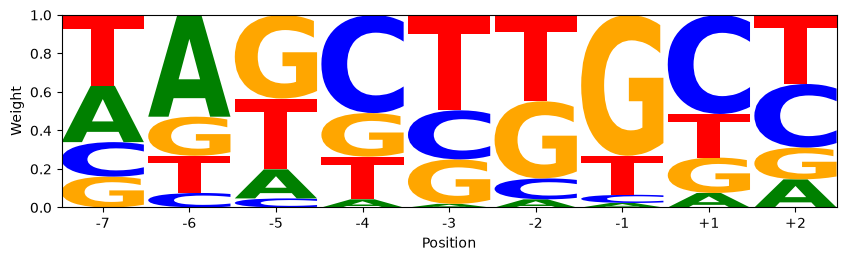

In [82]:
import logomaker
import matplotlib.pyplot as plt


weighted_matrix = pd.DataFrame(
    count_dicts,
    index=range(9)
).fillna(0)

weighted_matrix = weighted_matrix[["A", "C", "G", "T"]]

weighted_matrix = weighted_matrix.div(
    weighted_matrix.sum(axis=1),
    axis=0
)

# Create the logo object
logo = logomaker.Logo(weighted_matrix,
                      shade_below=0.5)

# Style the figure
logo.style_xticks(rotation=0, fmt='%d', anchor=0)
ax = logo.ax

positions = range(len(weighted_matrix)) 
custom_labels = ['-7', '-6', '-5', '-4', '-3', '-2', '-1', '+1', '+2'] 
ax.set_xticks(positions, labels=custom_labels)


ax.set_ylabel('Weight')
ax.set_xlabel('Position')

plt.show()

In [83]:
# rep

count_minus7 = {}
count_minus6 = {}
count_minus5 = {}
count_minus4 = {}
count_minus3 = {}
count_minus2 = {}
count_minus1 = {}
count_plus1 = {}
count_plus2 = {}

count_dicts = [
    count_minus7,
    count_minus6,
    count_minus5,
    count_minus4,
    count_minus3,
    count_minus2,
    count_minus1,
    count_plus1,
    count_plus2,
]


def count_bases(row):
    oriT_seq = row["ori_seq"]

    for i, base in enumerate(oriT_seq[:9]):
        count_dicts[i][base] = count_dicts[i].get(base, 0) + 1


df_rep.apply(count_bases, axis = 1)

base_counts = pd.DataFrame(
    count_dicts,
    index=["-7", "-6", "-5", "-4", "-3", "-2", "-1", "+1", "+2"]
).fillna(0).astype(int)

print(base_counts)

base_freq = base_counts.div(base_counts.sum(axis=1), axis=0)

print(base_freq)

      T   G    C    A
-7  142  12   34   29
-6   10   4    5  198
-5   30  88   12   87
-4  206   0    6    5
-3   33  27   20  137
-2  144   8   42   23
-1  202   6    6    3
+1    0   0    0  217
+2    0   0  217    0
           T         G         C         A
-7  0.654378  0.055300  0.156682  0.133641
-6  0.046083  0.018433  0.023041  0.912442
-5  0.138249  0.405530  0.055300  0.400922
-4  0.949309  0.000000  0.027650  0.023041
-3  0.152074  0.124424  0.092166  0.631336
-2  0.663594  0.036866  0.193548  0.105991
-1  0.930876  0.027650  0.027650  0.013825
+1  0.000000  0.000000  0.000000  1.000000
+2  0.000000  0.000000  1.000000  0.000000


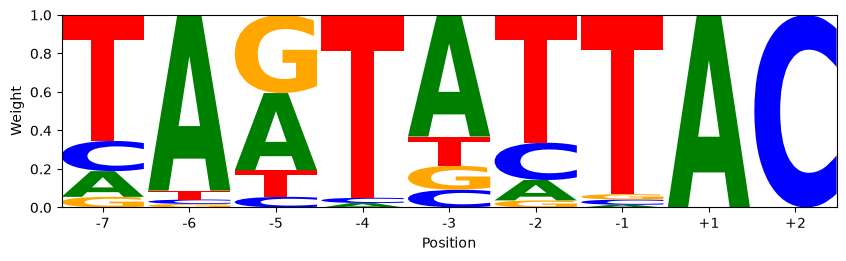

In [84]:
import logomaker
import matplotlib.pyplot as plt


weighted_matrix = pd.DataFrame(
    count_dicts,
    index=range(9)
).fillna(0)

weighted_matrix = weighted_matrix[["A", "C", "G", "T"]]

weighted_matrix = weighted_matrix.div(
    weighted_matrix.sum(axis=1),
    axis=0
)

# Create the logo object
logo = logomaker.Logo(weighted_matrix,
                      shade_below=0.5)

# Style the figure
logo.style_xticks(rotation=0, fmt='%d', anchor=0)
ax = logo.ax

positions = range(len(weighted_matrix)) 
custom_labels = ['-7', '-6', '-5', '-4', '-3', '-2', '-1', '+1', '+2'] 
ax.set_xticks(positions, labels=custom_labels)


ax.set_ylabel('Weight')
ax.set_xlabel('Position')

plt.show()

In [86]:
df_new_relaxase = pd.read_csv("../data/processed/unique_relaxase_oriT_dataset.csv")

df_new_rep = pd.read_csv("../data/processed/unique_rep_oriR_dataset.csv")

df_new_rep.rename(columns={"sDBM_pos": "sDBM_pos", "sDBM": "sDBM", "ori_seq": "ori_nic_seq", "rep_amino_acid_seq": "amino_acid_seq"}, inplace=True)
df_new_relaxase.rename(columns={"sDBM_pos": "sDBM_pos", "sDBM": "sDBM", "oriT_nic_seq": "ori_nic_seq", "relaxase_sequence": "amino_acid_seq"}, inplace=True)

df = pd.concat([df_new_relaxase, df_new_rep], ignore_index=True)

df

,sDBM_pos,sDBM,ori_nic_seq,amino_acid_seq
0,"(4, 12)",HVPMRSIKK,TATCCTGCC,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...
1,"(4, 12)",HLTAKTGSR,AAGTGCGCC,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...
2,"(4, 12)",VEKDYRVKR,TATCCTGCA,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...
3,"(2, 10)",IAKRENGKR,AAGTGCGCC,MTIAKRENGKRSLIAMASYRSGEKLYSELYEKTNLYNHRTVKPEAF...
4,"(2, 10)",SISSIKGDA,CGGGTGTGG,MLSISSIKGDAGYYSHEDNYYASGSLDSRWMGEGAEKLGLKGEVAS...
...,...,...,...,...
424,"(88, 96)",HPNIQGAKS,TAAAAATAC,MPRAGRFSIKAKNYFLTYPQCSLSKEEALSQLQNLITPTNKKYIKI...
425,"(88, 96)",HPNIQGAKS,TACTAATAC,MPPPNKFRINAKNYFLTYPRCSLTKEEALSQIKALETPISKLFIRI...
426,"(88, 96)",HPNVQGAKS,TTATACTAC,MAPPKRFQINAKNYFLTYPQCSLTKEEALSQLRSLRTPTNQKYIKV...
427,"(88, 96)",HPNIQGAKS,TTATCCTAC,MSRPKGFRVNAKNFFLTYPRCSLSKEAALEQLQNIQTNVNKKFIRV...


In [87]:
def get_dna_encoding(ori_seq):

    dna_vec_list = []

    for base in ori_seq:
        match base:
            case 'A':
                dna_vec_list.append(0)
            case 'C':
                dna_vec_list.append(1)
            case 'G':
                dna_vec_list.append(2)
            case 'T':  
                dna_vec_list.append(3)

    #convert to tensor
    dna_encoding = torch.tensor(dna_vec_list, dtype=torch.long)

    return dna_encoding

In [93]:
# double check that halving the embedding works (to the best of knowledge no shuffling till this point) -> rn it has both negative + positive instances
embedding_tensor = torch.load("../data/embeddings/full_sDBM_embeddings.pt")[:429,:,:]

ori_tensor_list = []


for index, row in df.iterrows():

    ori_seq = row.values[2]

    dna_encoding = get_dna_encoding(ori_seq)


# accumulating embeddings on the gpu -> save them on cpu instead
    ori_tensor_list.append(dna_encoding.unsqueeze(dim=0))


ori_encoding_tensor = torch.stack(ori_tensor_list, dim = 0)

ori_encoding = ori_encoding_tensor.flatten(-2)

print(embedding_tensor.shape)
print(ori_encoding.shape)

print(ori_encoding)


torch.Size([429, 9, 960])
torch.Size([429, 9])
tensor([[3, 0, 3,  ..., 2, 1, 1],
        [0, 0, 2,  ..., 2, 1, 1],
        [3, 0, 3,  ..., 2, 1, 0],
        ...,
        [3, 3, 0,  ..., 3, 0, 1],
        [3, 3, 0,  ..., 3, 0, 1],
        [1, 0, 0,  ..., 3, 0, 1]])


In [94]:
import ast

from sklearn.preprocessing import StandardScaler
scaleStandard = StandardScaler()
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt

import random

pca1 = PCA()


pca2 = PCA(0.50)


embed_np = embedding_tensor.cpu().numpy()


reduced_residue_embeddings = []

for i in range(0, 9):

    residue_embed = embed_np[:, i, :]

    residue_embed_scaled = scaleStandard.fit_transform(residue_embed)

    residue_embed_pca2 = pca2.fit_transform(residue_embed_scaled)

    reduced_residue_embeddings.append(torch.from_numpy(residue_embed_pca2))

    print(residue_embed_pca2.shape)

sDBM_embedding = torch.concat(reduced_residue_embeddings, dim = 1)

print(sDBM_embedding.shape)

(429, 7)
(429, 6)
(429, 8)
(429, 7)
(429, 9)
(429, 8)
(429, 10)
(429, 8)
(429, 8)
torch.Size([429, 71])


In [95]:
X = sDBM_embedding

y = ori_encoding

print(X.shape)
print(y.shape)

torch.Size([429, 71])
torch.Size([429, 9])


In [96]:
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split


class CustomDataset(Dataset):
    # required dunder methods
    def __init__(self, data, target):
        self.data = torch.tensor(data, dtype = torch.float32)
        self.target = torch.tensor(target, dtype=torch.long)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        sample_x = self.data[index] #instead of tensor(self.data) -> avoid UserWarning
        sample_y = self.target[index]

        return sample_x, sample_y


full_dataset = CustomDataset(X, y)

/tmp/ipykernel_1232/4275186655.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.data = torch.tensor(data, dtype = torch.float32)
/tmp/ipykernel_1232/4275186655.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.target = torch.tensor(target, dtype=torch.long)


In [97]:
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

print(f"Training Set: {train_size}")
print(f"Validation Set: {val_size}")

train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

x_val_dataset = torch.stack([val_dataset[i][0] for i in range(len(val_dataset))])
y_val_dataset = torch.stack([val_dataset[i][1] for i in range(len(val_dataset))])

train_dataloader = DataLoader(dataset=train_dataset, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)


Training Set: 343
Validation Set: 86


Machine Learning

In [126]:
from torch import nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cuda


In [134]:
# designing neural network architecture -> change no of hidden layers/no of neurons in each layer/activation function

class MultiHeadFourClassClassiferNN(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        #initialise nn.Module parent class constructor
        super().__init__()

        # self.fc1 = nn.Linear(in_features=input_dim, out_features=hidden_dim)
        # self.relu = nn.ReLU()
        # self.dropout = nn.Dropout(p=0.3)
        # self.fc2 = nn.Linear(in_features=hidden_dim, out_features=9)

        self.shared_backbone = nn.Linear(in_features=input_dim, out_features=hidden_dim)

        self.relu = nn.ReLU()

        self.heads = nn.ModuleList([nn.Linear(hidden_dim, 4) for _ in range(9)])

    def forward(self, x):

        # returns -> 9, B, 4 ?

        # x = self.relu(self.fc1(x))
        # x = self.dropout(x)
        # return self.fc2(x)
        x = self.relu(self.shared_backbone(x))
        x = [head(x) for head in self.heads]
        return x

In [ ]:
# designing neural network architecture -> change no of hidden layers/no of neurons in each layer/activation function

class MultiHeadFourClassClassiferNN(nn.Module):
    def __init__(self, input_dim, hidden_dim1, hidden_dim2):
        #initialise nn.Module parent class constructor
        super().__init__()

        # self.fc1 = nn.Linear(in_features=input_dim, out_features=hidden_dim)
        # self.relu = nn.ReLU()
        # self.dropout = nn.Dropout(p=0.3)
        # self.fc2 = nn.Linear(in_features=hidden_dim, out_features=9)

        self.shared_backbone1 = nn.Linear(in_features=input_dim, out_features=hidden_dim1)

        self.shared_backbone2 = nn.Linear(in_features=hidden_dim1, out_features=hidden_dim2)

        self.relu = nn.ReLU()

        self.dropout = nn.Dropout(p=0.3)

        self.heads = nn.ModuleList([nn.Linear(hidden_dim2, 4) for _ in range(9)])

    def forward(self, x):

        # returns -> 9, B, 4 ?

        # x = self.relu(self.fc1(x))
        # x = self.dropout(x)
        # return self.fc2(x)
        x = self.relu(self.shared_backbone1(x))
        x = self.dropout()
        x = self.relu(self.shared_backbone2(x))
        x = self.dropout()
        x = [head(x) for head in self.heads]
        return x

In [147]:
oriT_predictor = MultiHeadFourClassClassiferNN(71, 32, 32).to(device)

oriT_predictor.state_dict() # random parameters before training
next(oriT_predictor.parameters()).device

# set up the loss function
loss_fn = nn.CrossEntropyLoss() #interally applies softmax

# 0.001 worked well
optimiser = torch.optim.Adam(oriT_predictor.parameters(), lr=0.0005)

def accuracy_fn(y_true, y_pred):
    pass

    correct_pred = torch.eq(y_true, y_pred).sum().item()
    total_pred = y_true.numel() #across all batches (over 9 positions)

    accuracy = (correct_pred/total_pred) * 100

    return accuracy

In [148]:
torch.manual_seed(3242)

epochs = 150

acc = []
acc_val = []

for epoch in range(epochs):

    # =========================
    # Training
    # =========================
    oriT_predictor.train()

    running_loss = 0.0
    running_acc = 0.0

    for batch_idx, (inputs, targets) in enumerate(train_dataloader):

        # Send tensors to device
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        # Forward pass
        y_logits = torch.stack(oriT_predictor(inputs), dim = 0) #convert [] -> tensor along extra dimension
        y_logits_permuted = y_logits.permute(1, 2, 0) #permute tensor to B, C, 9

        # Predictions
        y_pred = torch.argmax(y_logits_permuted, dim = 1)

        # Accuracy
        accuracy = accuracy_fn(targets, y_pred)

        # Loss
        # CrossEntropyLoss expects logits directly (no softmax)
        loss = loss_fn(y_logits_permuted, targets)

        # Backpropagation
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()

        # Accumulate metrics
        running_loss += loss.item()
        running_acc += accuracy


    # Average training metrics
    epoch_loss = running_loss / len(train_dataloader)
    epoch_acc = running_acc / len(train_dataloader)


    # =========================
    # Validation / Test
    # =========================
    oriT_predictor.eval()

    with torch.inference_mode():

        test_inputs = x_val_dataset.to(device, non_blocking=True)
        test_targets = y_val_dataset.to(device, non_blocking=True)

        test_logits = torch.stack(oriT_predictor(test_inputs), dim = 0) #convert [] -> tensor along extra dimension
        test_logits_permuted = test_logits.permute(1, 2, 0) #permute tensor to B, C, 9

        test_pred = torch.argmax(test_logits_permuted, dim = 1)

        test_loss = loss_fn(test_logits_permuted, test_targets)

        test_accuracy = accuracy_fn(test_targets, test_pred)


    # =========================
    # Record / print
    # =========================
    if (epoch + 1) % 1 == 0:

        acc.append(epoch_acc)
        acc_val.append(test_accuracy)

        print(
            f"Epoch: {epoch+1:02d}/{epochs} | "
            f"Training Loss: {epoch_loss:.4f} | "
            f"Training Accuracy: {epoch_acc:.4f} | "
            f"Test Loss: {test_loss.item():.4f} | "
            f"Test Accuracy: {test_accuracy:.4f}"
        )

TypeError: Dropout.forward() got an unexpected keyword argument 'p'

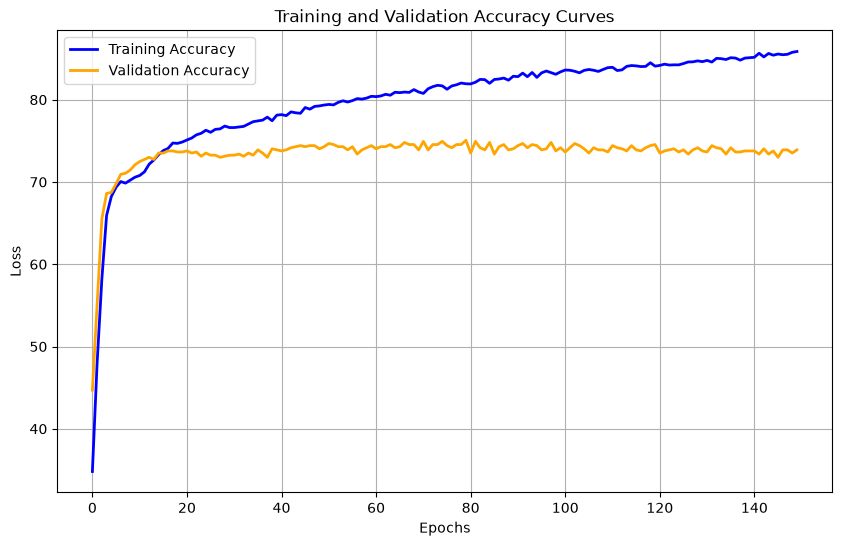

In [145]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(acc, label='Training Accuracy', color='blue', linewidth=2)
plt.plot(acc_val, label='Validation Accuracy', color='orange', linewidth=2)
plt.title('Training and Validation Accuracy Curves')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [111]:
# Print entire dataset!

print(len(df))
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(df) 

429


,sDBM_pos,sDBM,ori_nic_seq,amino_acid_seq
0,"(4, 12)",HVPMRSIKK,TATCCTGCC,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...
1,"(4, 12)",HLTAKTGSR,AAGTGCGCC,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...
2,"(4, 12)",VEKDYRVKR,TATCCTGCA,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...
3,"(2, 10)",IAKRENGKR,AAGTGCGCC,MTIAKRENGKRSLIAMASYRSGEKLYSELYEKTNLYNHRTVKPEAF...
4,"(2, 10)",SISSIKGDA,CGGGTGTGG,MLSISSIKGDAGYYSHEDNYYASGSLDSRWMGEGAEKLGLKGEVAS...
5,"(2, 10)",SHMVLTRQD,ATTGTCTAT,MLSHMVLTRQDIGRAASYYEDGADDYYAKDGDASEWQGKGAEELGL...
6,"(4, 12)",HLTAKTGSR,AAATGCGCC,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...
7,"(2, 10)",DITTITRQN,TAGGTGTAT,MLDITTITRQNVTSVVGYYSDAKDDYYSKDSSFTSWQGTGAEALGL...
8,"(2, 10)",SFSVVKSAG,AGTGTGTGG,MLSFSVVKSAGSAGNYYTDKDNYYVLGSMGERWAGQGAEQLGLQGS...
9,"(4, 12)",HVPMRSLGK,CATCCTGCC,MIAKHVPMRSLGKSDFAGLANYITDAQSKDHRLGHVQATNCEAGSI...


In [ ]:
final_df.to_csv('../data/processed/final_rep_virus_dataset.csv', index=False)